# Predicción del nivel de obesidad a partir de hábitos alimenticios y condición física usando Random Forest

**Método:** Random Forest para clasificación multiclase

---

## Descripción del problema

La obesidad es uno de los principales problemas de salud pública en Latinoamérica: está asociada a diabetes tipo 2, enfermedades cardiovasculares e hipertensión. Detectar a tiempo qué personas están en riesgo, **a partir de sus hábitos de vida**, permite enfocar campañas de prevención.

En este notebook se construye un sistema inteligente que **clasifica a una persona en uno de 7 niveles de peso** (desde *peso insuficiente* hasta *obesidad tipo III*) usando el algoritmo **Random Forest**.

## Dataset

*Estimation of obesity levels based on eating habits and physical condition* (UCI Machine Learning Repository, ID 544).
Palechor, F. M., & De la Hoz Manotas, A. (2019). *Data in Brief*, 25, 104344.

- 2.111 registros de personas de **México, Perú y Colombia**, con 16 variables de entrada y 1 variable objetivo.
- El 23 % de los datos se recolectó con una encuesta web y el 77 % se generó sintéticamente con SMOTE (lo hicieron los autores para balancear las clases).

## Estructura del notebook

| Sección | Contenido |
|---|---|
| 0 | Configuración del entorno |
| 1 | Carga y comprensión de los datos |
| 2 | Limpieza y preprocesamiento |
| 3 | Entrenamiento (árbol de decisión base, Random Forest y ajuste de hiperparámetros) |
| 4 | Evaluación (métricas, matrices de confusión, validación cruzada, importancia de variables) |
| 5 | Guardado de los modelos para el despliegue |
| 6 | Conclusiones |

## Dos escenarios de experimentación

| Escenario | Variables usadas | Pregunta que responde |
|---|---|---|
| **A – Completo** | Todas, incluidas `Estatura` y `Peso` | ¿Qué tan bien clasifica el modelo con toda la información? |
| **B – Solo hábitos** | Todas **excepto** `Estatura` y `Peso` | ¿Se puede predecir el nivel de obesidad **solo con los hábitos de vida**? (útil para prevención) |

El escenario B es importante porque la clase objetivo se definió a partir del Índice de Masa Corporal (IMC = peso / estatura²). Con peso y estatura el problema es casi "calcular una fórmula"; sin ellos, el modelo tiene que aprender de verdad la relación entre los hábitos y la obesidad.

---
# 0. Configuración del entorno

## 0.1 Importación de librerías

- **pandas / numpy:** manipulación de datos.
- **matplotlib / seaborn:** gráficas.
- **scikit-learn:** modelos (árbol de decisión y Random Forest), partición de datos, búsqueda de hiperparámetros y métricas.
- **pickle:** guardar el modelo entrenado en un archivo `.pkl` para el despliegue.

In [2]:
# --- Manipulación de datos ---
import numpy as np
import pandas as pd

# --- Visualización ---
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# --- Modelos ---
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# --- Partición, validación y búsqueda de hiperparámetros ---
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RandomizedSearchCV, cross_validate)

# --- Métricas de evaluación ---
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.inspection import permutation_importance

# --- Guardado del modelo ---
import pickle
from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

## 0.2 Configuración global

Se fija una **semilla aleatoria** para que los resultados sean reproducibles: Random Forest usa aleatoriedad tanto en el *bootstrap* (muestreo de filas) como en la selección de variables de cada división. También se define un estilo uniforme para todas las gráficas.

In [3]:
# Semilla para reproducibilidad de todos los procesos aleatorios
SEMILLA = 42
np.random.seed(SEMILLA)

# Paleta de colores (consistente en todas las gráficas)
AZUL, NARANJA, VERDE_AGUA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA_SEC, GRIS = "#0b0b0b", "#52514e", "#898781"
FONDO, REJILLA, EJE = "#fcfcfb", "#e1e0d9", "#c3c2b7"

# Mapa de color secuencial (un solo tono azul, de claro a oscuro) para matrices de confusión
CMAP_AZUL = LinearSegmentedColormap.from_list(
    "azul", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

# Estilo general de matplotlib: fondo claro, rejilla tenue, sin bordes superiores/derechos
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": EJE, "axes.labelcolor": TINTA_SEC, "axes.titlecolor": TINTA,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.6,
    "xtick.color": GRIS, "ytick.color": GRIS, "text.color": TINTA,
    "legend.frameon": False, "figure.dpi": 100,
    "axes.axisbelow": True,          # la rejilla queda detrás de las barras
})

# Carpeta donde se guardan las figuras (para usarlas en el artículo y las diapositivas)
CARPETA_FIG = Path("figuras")
CARPETA_FIG.mkdir(exist_ok=True)

def guardar_figura(nombre):
    # Guarda la figura actual en alta resolución dentro de la carpeta 'figuras'
    plt.savefig(CARPETA_FIG / f"{nombre}.png", dpi=200, bbox_inches="tight")

---
# 1. Carga y comprensión de los datos

## 1.1 Carga del dataset

El archivo `ObesityDataSet_raw_and_data_sinthetic.csv` debe estar en la misma carpeta que este notebook.

In [4]:
# Lectura del archivo CSV en un DataFrame de pandas
df_original = pd.read_csv("ObesityDataSet_raw_and_data_sinthetic.csv")

# Se trabaja sobre una copia para conservar intactos los datos originales
df = df_original.copy()

print(f"Filas: {df.shape[0]}  |  Columnas: {df.shape[1]}")
df.head()

Filas: 2111  |  Columnas: 17


,Age,Gender,Height,Weight,CALC,FAVC,FCVC,NCP,SCC,SMOKE,CH2O,family_history_with_overweight,FAF,TUE,CAEC,MTRANS,NObeyesdad
0,21.0,Female,1.62,64.0,no,no,2.0,3.0,no,no,2.0,yes,0.0,1.0,Sometimes,Public_Transportation,Normal_Weight
1,21.0,Female,1.52,56.0,Sometimes,no,3.0,3.0,yes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,23.0,Male,1.80,77.0,Frequently,no,2.0,3.0,no,no,2.0,yes,2.0,1.0,Sometimes,Public_Transportation,Normal_Weight
3,27.0,Male,1.80,87.0,Frequently,no,3.0,3.0,no,no,2.0,no,2.0,0.0,Sometimes,Walking,Overweight_Level_I
4,22.0,Male,1.78,89.8,Sometimes,no,2.0,1.0,no,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


## 1.2 Diccionario de variables

| Variable original | Nombre en español | Descripción | Tipo |
|---|---|---|---|
| `Gender` | Genero | Género | Categórica binaria |
| `Age` | Edad | Edad en años | Numérica |
| `Height` | Estatura | Estatura en metros | Numérica |
| `Weight` | Peso | Peso en kilogramos | Numérica |
| `family_history_with_overweight` | Antecedente_familiar | ¿Algún familiar ha sufrido sobrepeso? | Binaria |
| `FAVC` | Comida_calorica | ¿Come con frecuencia alimentos altos en calorías? | Binaria |
| `FCVC` | Consumo_verduras | Frecuencia de consumo de verduras (1 = nunca, 2 = a veces, 3 = siempre) | Ordinal |
| `NCP` | Comidas_principales | Número de comidas principales al día (1 a 4) | Ordinal |
| `CAEC` | Come_entre_comidas | ¿Come entre comidas? (no / a veces / frecuentemente / siempre) | Ordinal |
| `SMOKE` | Fuma | ¿Fuma? | Binaria |
| `CH2O` | Consumo_agua | Litros de agua al día (1 = < 1 L, 2 = 1–2 L, 3 = > 2 L) | Ordinal |
| `SCC` | Monitorea_calorias | ¿Monitorea las calorías que consume? | Binaria |
| `FAF` | Actividad_fisica | Frecuencia de actividad física (0 = nunca … 3 = 4–5 días por semana) | Ordinal |
| `TUE` | Uso_tecnologia | Tiempo diario frente a dispositivos (0 = 0–2 h, 1 = 3–5 h, 2 = > 5 h) | Ordinal |
| `CALC` | Consumo_alcohol | Frecuencia de consumo de alcohol (no / a veces / frecuentemente / siempre) | Ordinal |
| `MTRANS` | Transporte | Medio de transporte habitual | Categórica nominal |
| **`NObeyesdad`** | **Nivel_obesidad** | **Variable objetivo: 7 niveles de peso** | **Categórica (objetivo)** |

## 1.3 Estructura y tipos de datos

In [5]:
# Información general: tipo de dato de cada columna y cantidad de valores no nulos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Age                             2111 non-null   float64
 1   Gender                          2111 non-null   str    
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   CALC                            2111 non-null   str    
 5   FAVC                            2111 non-null   str    
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   SCC                             2111 non-null   str    
 9   SMOKE                           2111 non-null   str    
 10  CH2O                            2111 non-null   float64
 11  family_history_with_overweight  2111 non-null   str    
 12  FAF                             2111 non-null

In [6]:
# Estadísticas descriptivas de las variables numéricas (media, desviación, mínimo, cuartiles, máximo)
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,2111.0,24.31,6.35,14.00,19.95,22.78,26.00,61.00
Height,2111.0,1.70,0.09,1.45,1.63,1.70,1.77,1.98
Weight,2111.0,86.59,26.19,39.00,65.47,83.00,107.43,173.00
FCVC,2111.0,2.42,0.53,1.00,2.00,2.39,3.00,3.00
NCP,2111.0,2.69,0.78,1.00,2.66,3.00,3.00,4.00
CH2O,2111.0,2.01,0.61,1.00,1.58,2.00,2.48,3.00
FAF,2111.0,1.01,0.85,0.00,0.12,1.00,1.67,3.00
TUE,2111.0,0.66,0.61,0.00,0.00,0.63,1.00,2.00


In [7]:
# Valores únicos de cada variable categórica, para detectar categorías raras o mal escritas
for col in df.select_dtypes(exclude="number").columns:
    print(f"{col}: {df[col].value_counts().to_dict()}\n")

Gender: {'Male': 1068, 'Female': 1043}

CALC: {'Sometimes': 1401, 'no': 639, 'Frequently': 70, 'Always': 1}

FAVC: {'yes': 1866, 'no': 245}

SCC: {'no': 2015, 'yes': 96}

SMOKE: {'no': 2067, 'yes': 44}

family_history_with_overweight: {'yes': 1726, 'no': 385}

CAEC: {'Sometimes': 1765, 'Frequently': 242, 'Always': 53, 'no': 51}

MTRANS: {'Public_Transportation': 1580, 'Automobile': 457, 'Walking': 56, 'Motorbike': 11, 'Bike': 7}

NObeyesdad: {'Obesity_Type_I': 351, 'Obesity_Type_III': 324, 'Obesity_Type_II': 297, 'Overweight_Level_I': 290, 'Overweight_Level_II': 290, 'Normal_Weight': 287, 'Insufficient_Weight': 272}



## 1.4 Distribución de la variable objetivo

Antes de entrenar hay que revisar si las clases están **balanceadas**. Si una clase dominara, el modelo tendería a predecirla siempre y el *Accuracy* sería engañoso.

,Registros,Porcentaje (%)
NObeyesdad,,
Insufficient_Weight,272,12.9
Normal_Weight,287,13.6
Overweight_Level_I,290,13.7
Overweight_Level_II,290,13.7
Obesity_Type_I,351,16.6
Obesity_Type_II,297,14.1
Obesity_Type_III,324,15.3


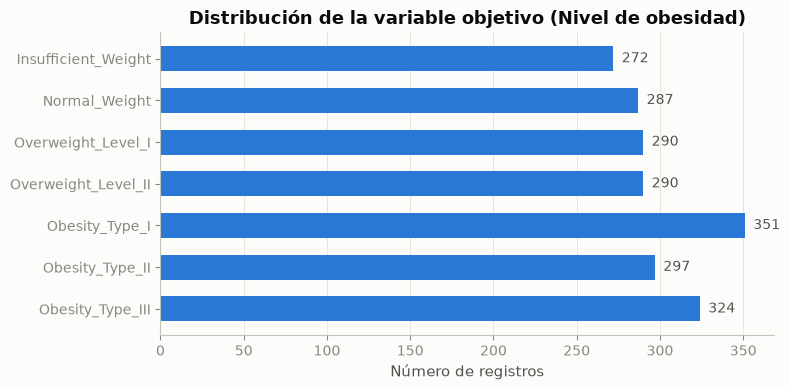

In [8]:
# Orden lógico de las clases: de menor a mayor nivel de peso
ORDEN_CLASES = ["Insufficient_Weight", "Normal_Weight", "Overweight_Level_I",
                "Overweight_Level_II", "Obesity_Type_I", "Obesity_Type_II",
                "Obesity_Type_III"]

# Conteo y porcentaje de registros por clase
conteo = df["NObeyesdad"].value_counts().reindex(ORDEN_CLASES)
porcentaje = (conteo / len(df) * 100).round(1)
display(pd.DataFrame({"Registros": conteo, "Porcentaje (%)": porcentaje}))

# Gráfica de barras horizontales con la cantidad de registros por clase
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(ORDEN_CLASES, conteo.values, color=AZUL, height=0.6)
ax.invert_yaxis()                      # la primera clase queda arriba
ax.grid(axis="y", visible=False)       # solo rejilla vertical
for i, v in enumerate(conteo.values):  # etiqueta con el conteo al final de cada barra
    ax.text(v + 5, i, str(v), va="center", color=TINTA_SEC, fontsize=10)
ax.set_title("Distribución de la variable objetivo (Nivel de obesidad)")
ax.set_xlabel("Número de registros")
plt.tight_layout(); guardar_figura("01_distribucion_clases"); plt.show()

**Observación:** las 7 clases tienen entre 272 y 351 registros (entre el 12,9 % y el 16,6 % cada una). El dataset está **balanceado**, así que no se necesitan técnicas de sobremuestreo y el *Accuracy* sí es una métrica representativa. Igual se reporta el **F1-score macro**, que le da el mismo peso a todas las clases.

---
# 2. Limpieza y preprocesamiento

## 2.1 Renombrar columnas al español

Se usan nombres descriptivos en español para que el código, las gráficas y el despliegue sean más fáciles de leer.

In [9]:
# Diccionario: nombre original -> nombre en español
NOMBRES = {
    "Gender": "Genero", "Age": "Edad", "Height": "Estatura", "Weight": "Peso",
    "family_history_with_overweight": "Antecedente_familiar",
    "FAVC": "Comida_calorica", "FCVC": "Consumo_verduras",
    "NCP": "Comidas_principales", "CAEC": "Come_entre_comidas", "SMOKE": "Fuma",
    "CH2O": "Consumo_agua", "SCC": "Monitorea_calorias", "FAF": "Actividad_fisica",
    "TUE": "Uso_tecnologia", "CALC": "Consumo_alcohol", "MTRANS": "Transporte",
    "NObeyesdad": "Nivel_obesidad",
}
df = df.rename(columns=NOMBRES)

# Variable objetivo (se usa en todo el notebook)
OBJETIVO = "Nivel_obesidad"
df.columns.tolist()

['Edad',
 'Genero',
 'Estatura',
 'Peso',
 'Consumo_alcohol',
 'Comida_calorica',
 'Consumo_verduras',
 'Comidas_principales',
 'Monitorea_calorias',
 'Fuma',
 'Consumo_agua',
 'Antecedente_familiar',
 'Actividad_fisica',
 'Uso_tecnologia',
 'Come_entre_comidas',
 'Transporte',
 'Nivel_obesidad']

## 2.2 Valores faltantes

In [10]:
# Cantidad de valores nulos por columna
nulos = df.isnull().sum()
print(nulos)
print(f"\nTotal de valores faltantes: {nulos.sum()}")

Edad                    0
Genero                  0
Estatura                0
Peso                    0
Consumo_alcohol         0
Comida_calorica         0
Consumo_verduras        0
Comidas_principales     0
Monitorea_calorias      0
Fuma                    0
Consumo_agua            0
Antecedente_familiar    0
Actividad_fisica        0
Uso_tecnologia          0
Come_entre_comidas      0
Transporte              0
Nivel_obesidad          0
dtype: int64

Total de valores faltantes: 0


**Resultado:** el dataset **no tiene valores faltantes**, así que no hay que imputar nada.

## 2.3 Corrección de variables ordinales con decimales (efecto de SMOTE)

Variables como `Consumo_verduras`, `Comidas_principales`, `Consumo_agua`, `Actividad_fisica` y `Uso_tecnologia` son **respuestas de una encuesta con opciones discretas** (por ejemplo, 1, 2 o 3). Sin embargo, el 77 % de los datos se generó con **SMOTE**, que interpola entre registros y produce valores "imposibles" como `2,4507` en la frecuencia de consumo de verduras.

**Decisión:** redondear esas variables al entero más cercano para que vuelvan a representar respuestas válidas de la encuesta. La `Edad` también se redondea a años enteros.

In [11]:
# Variables ordinales que en la encuesta original solo aceptan valores enteros
ORDINALES_NUM = ["Consumo_verduras", "Comidas_principales", "Consumo_agua",
                 "Actividad_fisica", "Uso_tecnologia"]

# Cuántos registros tienen valores decimales en cada variable ANTES de corregir
decimales_antes = {c: int((df[c] % 1 != 0).sum()) for c in ORDINALES_NUM + ["Edad"]}
print("Registros con decimales (antes):", decimales_antes)

# Redondeo al entero más cercano y conversión a tipo entero
df[ORDINALES_NUM + ["Edad"]] = df[ORDINALES_NUM + ["Edad"]].round().astype(int)

# Verificación: los valores ahora son solo enteros dentro del rango esperado
for c in ORDINALES_NUM:
    print(f"{c}: valores únicos = {sorted(df[c].unique())}")

Registros con decimales (antes): {'Consumo_verduras': 826, 'Comidas_principales': 640, 'Consumo_agua': 1290, 'Actividad_fisica': 1208, 'Uso_tecnologia': 1153, 'Edad': 1375}
Consumo_verduras: valores únicos = [np.int64(1), np.int64(2), np.int64(3)]
Comidas_principales: valores únicos = [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Consumo_agua: valores únicos = [np.int64(1), np.int64(2), np.int64(3)]
Actividad_fisica: valores únicos = [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
Uso_tecnologia: valores únicos = [np.int64(0), np.int64(1), np.int64(2)]


## 2.4 Registros duplicados

Los registros idénticos no aportan información nueva. Además, si una copia queda en entrenamiento y otra en prueba, la evaluación sale **optimista** (el modelo "ya vio" ese ejemplo).

In [12]:
# Conteo de filas completamente repetidas
n_duplicados = df.duplicated().sum()
print(f"Registros duplicados encontrados: {n_duplicados}")

# Eliminación de duplicados (se conserva la primera aparición)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Registros después de eliminar duplicados: {len(df)}")

Registros duplicados encontrados: 27
Registros después de eliminar duplicados: 2084


## 2.5 Categorías con muy pocos registros

En la sección 1.3 se vio que:
- `Consumo_alcohol` tiene **un solo registro** en la categoría `Always`.
- En `Transporte`, `Bike` (7) y `Motorbike` (11) tienen muy pocos registros.

Categorías tan pequeñas no permiten que el modelo aprenda patrones confiables. **Decisión:**
- Unir `Always` con `Frequently` en el consumo de alcohol, porque son las dos frecuencias más altas.
- Unir `Bike` y `Motorbike` en una categoría `Bike_Motorbike` (vehículos de dos ruedas).

In [13]:
# Consumo de alcohol: 'Always' (1 registro) se une a 'Frequently'
df["Consumo_alcohol"] = df["Consumo_alcohol"].replace({"Always": "Frequently"})

# Transporte: bicicleta y moto se agrupan en una sola categoría
df["Transporte"] = df["Transporte"].replace({"Bike": "Bike_Motorbike",
                                             "Motorbike": "Bike_Motorbike"})

print(df["Consumo_alcohol"].value_counts().to_dict())
print(df["Transporte"].value_counts().to_dict())

{'Sometimes': 1379, 'no': 635, 'Frequently': 70}
{'Public_Transportation': 1556, 'Automobile': 455, 'Walking': 55, 'Bike_Motorbike': 18}


## 2.6 Valores atípicos (outliers)

Se usa el criterio del **rango intercuartílico (IQR)**: un valor es atípico si está por debajo de Q1 − 1,5·IQR o por encima de Q3 + 1,5·IQR.

Edad       -> límites [11.00, 35.00]  |  atípicos: 160
Estatura   -> límites [1.42, 1.98]  |  atípicos: 1
Peso       -> límites [2.96, 171.06]  |  atípicos: 1


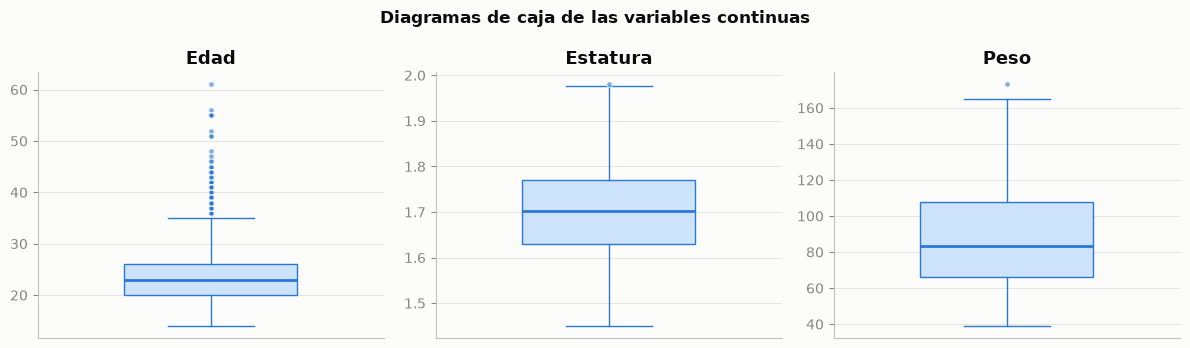

In [14]:
# Variables numéricas continuas a revisar
CONTINUAS = ["Edad", "Estatura", "Peso"]

# Conteo de atípicos por variable según el criterio IQR
for col in CONTINUAS:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_atipicos = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    print(f"{col:10s} -> límites [{lim_inf:.2f}, {lim_sup:.2f}]  |  atípicos: {n_atipicos}")

# Diagramas de caja para visualizar la dispersión y los atípicos
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col in zip(axes, CONTINUAS):
    ax.boxplot(df[col], vert=True, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#cde2fb", edgecolor=AZUL),
               medianprops=dict(color=AZUL, linewidth=2),
               whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL),
               flierprops=dict(marker="o", markersize=4, markerfacecolor=AZUL,
                               markeredgecolor=FONDO, alpha=0.6))
    ax.set_title(col); ax.set_xticks([])
plt.suptitle("Diagramas de caja de las variables continuas", fontweight="bold")
plt.tight_layout(); guardar_figura("02_boxplots_atipicos"); plt.show()

**Decisión: no se eliminan los atípicos.**
- Los atípicos de `Edad` corresponden a personas mayores de unos 35 años. Es poco frecuente en una muestra mayoritariamente joven, pero es completamente **real y válido**.
- Los de `Estatura` y `Peso` están dentro de rangos humanos normales (por ejemplo, 173 kg es consistente con obesidad tipo III).
- **Random Forest es robusto frente a atípicos**: sus árboles dividen los datos por umbrales (por ejemplo, `Edad > 30`), así que un valor extremo no distorsiona el modelo como sí pasaría en una regresión lineal.

## 2.7 Análisis exploratorio después de la limpieza

### 2.7.1 Relación entre el IMC y la variable objetivo

Se calcula el IMC **solo para el análisis exploratorio**, no como variable del modelo, para comprobar si la clase objetivo depende directamente del peso y la estatura.

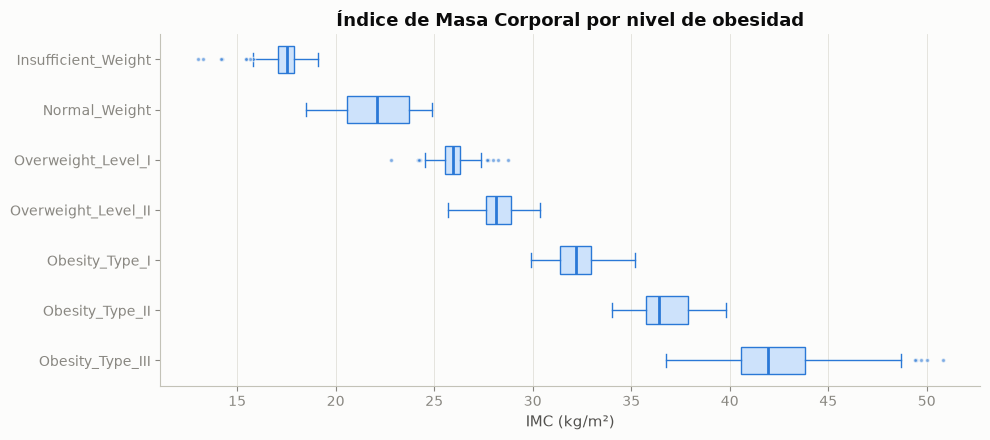

,min,median,max
Nivel_obesidad,,,
Insufficient_Weight,13.0,17.5,19.1
Normal_Weight,18.5,22.1,24.9
Overweight_Level_I,22.8,26.0,28.8
Overweight_Level_II,25.7,28.2,30.4
Obesity_Type_I,29.9,32.2,35.2
Obesity_Type_II,34.0,36.4,39.8
Obesity_Type_III,36.8,41.9,50.8


In [15]:
# IMC = peso (kg) / estatura (m)^2 -> solo para análisis, NO se usa como variable del modelo
imc = df["Peso"] / df["Estatura"] ** 2

# Diagrama de caja del IMC por cada nivel de obesidad
fig, ax = plt.subplots(figsize=(10, 4.5))
datos_imc = [imc[df[OBJETIVO] == c] for c in ORDEN_CLASES]
ax.boxplot(datos_imc, vert=False, widths=0.55, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor=AZUL),
           medianprops=dict(color=AZUL, linewidth=2),
           whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=AZUL,
                           markeredgecolor=FONDO, alpha=0.6))
ax.set_yticks(range(1, 8), ORDEN_CLASES)
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("IMC (kg/m²)")
ax.set_title("Índice de Masa Corporal por nivel de obesidad")
plt.tight_layout(); guardar_figura("03_imc_por_clase"); plt.show()

# Rango de IMC de cada clase
imc.groupby(df[OBJETIVO]).agg(["min", "median", "max"]).reindex(ORDEN_CLASES).round(1)

**Observación clave:** las cajas casi no se traslapan, porque **la clase objetivo se definió con rangos de IMC**. Por eso, con `Peso` y `Estatura` (escenario A), el modelo puede "reconstruir" el IMC y clasificar casi perfecto. Esto justifica el **escenario B (solo hábitos)**, que mide si los hábitos de vida tienen poder predictivo por sí solos.

### 2.7.2 Hábitos de vida frente al nivel de obesidad

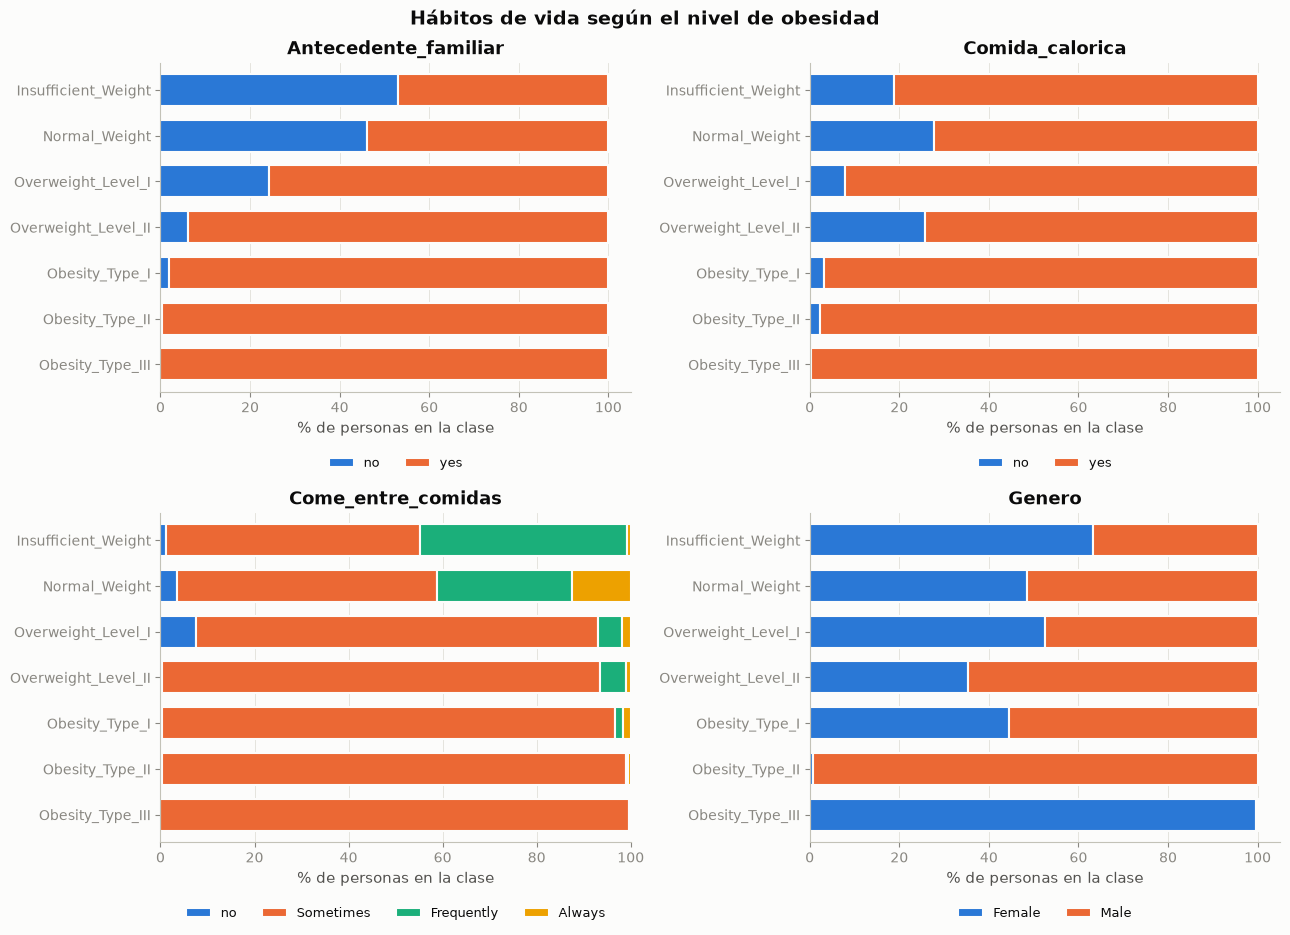

In [16]:
# Proporción de personas por nivel de obesidad para algunos hábitos binarios/categóricos
habitos = ["Antecedente_familiar", "Comida_calorica", "Come_entre_comidas", "Genero"]

# Orden lógico de las categorías de cada variable (para que las barras apiladas se lean bien)
ORDEN_CATEGORIAS = {"Antecedente_familiar": ["no", "yes"], "Comida_calorica": ["no", "yes"],
                    "Come_entre_comidas": ["no", "Sometimes", "Frequently", "Always"],
                    "Genero": ["Female", "Male"]}

fig, axes = plt.subplots(2, 2, figsize=(13, 9.5))
for ax, col in zip(axes.ravel(), habitos):
    # Tabla cruzada normalizada por fila: % de cada categoría dentro de cada clase
    tabla = pd.crosstab(df[OBJETIVO], df[col], normalize="index") * 100
    tabla = tabla.reindex(index=ORDEN_CLASES, columns=ORDEN_CATEGORIAS[col])
    tabla.plot(kind="barh", stacked=True, ax=ax, width=0.7, edgecolor=FONDO, linewidth=1.5,
               color=[AZUL, NARANJA, VERDE_AGUA, "#eda100"][:tabla.shape[1]])
    ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    ax.set_title(col); ax.set_xlabel("% de personas en la clase"); ax.set_ylabel("")
    # Leyenda debajo del eje para que no tape las barras
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=9)
plt.suptitle("Hábitos de vida según el nivel de obesidad", fontweight="bold", fontsize=14)
plt.tight_layout(); guardar_figura("04_habitos_vs_clase"); plt.show()

In [17]:
# Promedio de los hábitos numéricos (ordinales) por cada clase
df.groupby(OBJETIVO)[["Edad"] + ORDINALES_NUM].mean().reindex(ORDEN_CLASES).round(2)

,Edad,Consumo_verduras,Comidas_principales,Consumo_agua,Actividad_fisica,Uso_tecnologia
Nivel_obesidad,,,,,,
Insufficient_Weight,19.76,2.52,2.95,1.87,1.27,0.85
Normal_Weight,21.76,2.34,2.75,1.86,1.25,0.68
Overweight_Level_I,23.55,2.28,2.59,2.01,1.07,0.62
Overweight_Level_II,26.98,2.27,2.51,2.03,0.96,0.71
Obesity_Type_I,25.90,2.17,2.42,2.12,0.97,0.69
Obesity_Type_II,28.26,2.39,2.75,1.85,0.98,0.49
Obesity_Type_III,23.50,3.00,3.00,2.27,0.64,0.66


**Observaciones:**
- El **antecedente familiar de sobrepeso** aparece en el 98–100 % de las personas con obesidad, frente a cerca del 50 % en las de peso insuficiente o normal.
- El consumo frecuente de **comida calórica** y comer **"a veces" entre comidas** predominan en los niveles altos. Curiosamente, las personas de peso insuficiente o normal responden "Frequently" más a menudo (29–44 %). Es un patrón contraintuitivo que puede deberse a cómo se interpretó la pregunta de la encuesta o al proceso de generación sintética.
- La **actividad física** promedio disminuye a medida que aumenta el nivel de peso (de 1,27 a 0,64), y la **edad** promedio tiende a aumentar.

Estos patrones indican que los hábitos sí tienen información para predecir el nivel de obesidad (escenario B).

**Hallazgo importante sobre el género:** *Obesity_Type_II* es casi 100 % hombres y *Obesity_Type_III* es 100 % mujeres. Esto **no refleja la realidad**: es un artefacto de la generación sintética con SMOTE, que creó los registros de cada clase interpolando entre pocos registros reales. Lo mismo pasa con *Obesity_Type_III*, donde **todas** las personas reportan consumo de verduras = 3 y 3 comidas principales (tabla anterior). Hay que tenerlo en cuenta al interpretar el modelo, porque puede aprender estos atajos en lugar de patrones reales.

## 2.8 Codificación de variables

Random Forest de scikit-learn solo acepta **valores numéricos**, así que las variables de texto se transforman según su tipo:

| Tipo | Variables | Codificación |
|---|---|---|
| Binaria | Genero, Antecedente_familiar, Comida_calorica, Fuma, Monitorea_calorias | 0 / 1 |
| Ordinal | Come_entre_comidas, Consumo_alcohol | no = 0, Sometimes = 1, Frequently = 2, Always = 3 (respeta el orden) |
| Nominal | Transporte | *One-hot encoding* (una columna 0/1 por categoría) |

> Random Forest **no necesita escalar ni normalizar** las variables. Cada árbol divide por umbrales, así que la escala no afecta el resultado.

Los mapeos son fijos (no se "aprenden" de los datos), por lo que se pueden aplicar antes de partir los datos sin riesgo de **fuga de información** (*data leakage*). La misma función se reutilizará en el despliegue.

In [18]:
# Mapeos fijos para variables binarias y ordinales
MAPEO_BINARIO = {"yes": 1, "no": 0}
MAPEO_GENERO = {"Female": 0, "Male": 1}
MAPEO_ORDINAL = {"no": 0, "Sometimes": 1, "Frequently": 2, "Always": 3}

BINARIAS = ["Antecedente_familiar", "Comida_calorica", "Fuma", "Monitorea_calorias"]
ORDINALES_TXT = ["Come_entre_comidas", "Consumo_alcohol"]
CATEGORIAS_TRANSPORTE = ["Automobile", "Bike_Motorbike", "Public_Transportation", "Walking"]


def codificar(datos):
    # Convierte un DataFrame con las variables originales (texto) a formato numérico.
    # Se usa tanto para el entrenamiento como para predecir datos nuevos en el despliegue.
    X = datos.copy()
    X["Genero"] = X["Genero"].map(MAPEO_GENERO)
    for col in BINARIAS:
        X[col] = X[col].map(MAPEO_BINARIO)
    for col in ORDINALES_TXT:
        X[col] = X[col].map(MAPEO_ORDINAL)
    # One-hot de Transporte con categorías fijas (así siempre se generan las mismas columnas)
    for cat in CATEGORIAS_TRANSPORTE:
        X[f"Transporte_{cat}"] = (X["Transporte"] == cat).astype(int)
    return X.drop(columns="Transporte")


# Separación de variables de entrada (X) y variable objetivo (y)
X_completo = codificar(df.drop(columns=OBJETIVO))
y = df[OBJETIVO]

# Verificación: todas las columnas deben ser numéricas y sin nulos
print("¿Todas numéricas?:", X_completo.select_dtypes(exclude="number").empty)
print("Nulos tras codificar:", X_completo.isnull().sum().sum())
X_completo.head()

¿Todas numéricas?: True
Nulos tras codificar: 0


,Edad,Genero,Estatura,Peso,Consumo_alcohol,Comida_calorica,Consumo_verduras,Comidas_principales,Monitorea_calorias,Fuma,Consumo_agua,Antecedente_familiar,Actividad_fisica,Uso_tecnologia,Come_entre_comidas,Transporte_Automobile,Transporte_Bike_Motorbike,Transporte_Public_Transportation,Transporte_Walking
0,21,0,1.62,64.0,0,0,2,3,0,0,2,1,0,1,1,0,0,1,0
1,21,0,1.52,56.0,1,0,3,3,1,1,3,1,3,0,1,0,0,1,0
2,23,1,1.80,77.0,2,0,2,3,0,0,2,1,2,1,1,0,0,1,0
3,27,1,1.80,87.0,2,0,3,3,0,0,2,0,2,0,1,0,0,0,1
4,22,1,1.78,89.8,1,0,2,1,0,0,2,0,0,0,1,0,0,1,0


## 2.9 Definición de los dos escenarios

In [19]:
# Escenario A: todas las variables (incluye Peso y Estatura)
X_A = X_completo.copy()

# Escenario B: solo hábitos y datos demográficos (se excluyen Peso y Estatura)
X_B = X_completo.drop(columns=["Peso", "Estatura"])

ESCENARIOS = {"A - Completo": X_A, "B - Solo hábitos": X_B}
for nombre, X in ESCENARIOS.items():
    print(f"{nombre}: {X.shape[1]} variables")

A - Completo: 19 variables
B - Solo hábitos: 17 variables


## 2.10 Partición en entrenamiento y prueba

- **80 % entrenamiento** y **20 % prueba**.
- **Estratificada** (`stratify=y`): cada clase mantiene la misma proporción en los dos conjuntos.
- Se usan los **mismos índices** en ambos escenarios, para que la comparación sea justa (las mismas personas en prueba).
- El conjunto de prueba **no se toca** hasta la evaluación final.

In [20]:
# Partición estratificada de los índices (se reutiliza para ambos escenarios)
idx_train, idx_test = train_test_split(
    df.index, test_size=0.20, stratify=y, random_state=SEMILLA)

y_train, y_test = y.loc[idx_train], y.loc[idx_test]

# Diccionario con los conjuntos de cada escenario
DATOS = {nombre: (X.loc[idx_train], X.loc[idx_test]) for nombre, X in ESCENARIOS.items()}

print(f"Entrenamiento: {len(idx_train)} registros  |  Prueba: {len(idx_test)} registros\n")

# Verificación de la estratificación: proporciones por clase en cada conjunto
pd.DataFrame({
    "Entrenamiento (%)": (y_train.value_counts(normalize=True) * 100).round(1),
    "Prueba (%)": (y_test.value_counts(normalize=True) * 100).round(1),
}).reindex(ORDEN_CLASES)

Entrenamiento: 1667 registros  |  Prueba: 417 registros



,Entrenamiento (%),Prueba (%)
Nivel_obesidad,,
Insufficient_Weight,12.8,12.7
Normal_Weight,13.6,13.4
Overweight_Level_I,13.3,13.2
Overweight_Level_II,13.8,13.9
Obesity_Type_I,16.9,16.8
Obesity_Type_II,14.2,14.4
Obesity_Type_III,15.5,15.6


---
# 3. Entrenamiento de los modelos

## ¿Cómo funciona Random Forest?

Random Forest es un método de **ensamble** que combina muchos árboles de decisión:

1. **Bootstrap (bagging):** cada árbol se entrena con una muestra aleatoria **con reemplazo** del conjunto de entrenamiento. Cerca del 37 % de los registros queda por fuera de cada árbol: son las muestras ***out-of-bag* (OOB)**.
2. **Selección aleatoria de variables:** en cada división, el árbol solo puede elegir entre un subconjunto aleatorio de variables (`max_features`). Así los árboles quedan **poco correlacionados** entre sí.
3. **Votación por mayoría:** para clasificar un registro nuevo, cada árbol vota y gana la clase con más votos (en scikit-learn se promedian las probabilidades de los árboles).

Un árbol solo tiene **alta varianza**: es muy sensible a los datos con los que se entrena y tiende al sobreajuste. Promediar muchos árboles distintos **reduce esa varianza** sin aumentar el sesgo.

Se entrenan tres modelos por escenario:

| Modelo | Propósito |
|---|---|
| Árbol de decisión | **Línea base**: muestra cuánto mejora el ensamble frente a un solo árbol |
| Random Forest por defecto | Desempeño "de fábrica" del algoritmo |
| Random Forest ajustado | Hiperparámetros optimizados con búsqueda aleatoria y validación cruzada |

## 3.1 Modelo base: árbol de decisión

In [21]:
# Diccionario donde se guardarán todos los modelos entrenados: modelos[escenario][nombre_modelo]
modelos = {nombre: {} for nombre in ESCENARIOS}

for nombre, (X_train, X_test) in DATOS.items():
    # Árbol de decisión con parámetros por defecto (crece hasta que las hojas son puras)
    arbol = DecisionTreeClassifier(random_state=SEMILLA)
    arbol.fit(X_train, y_train)
    modelos[nombre]["Árbol de decisión"] = arbol
    print(f"{nombre}: profundidad = {arbol.get_depth()}, hojas = {arbol.get_n_leaves()}")

A - Completo: profundidad = 14, hojas = 99
B - Solo hábitos: profundidad = 19, hojas = 455


## 3.2 Random Forest con parámetros por defecto

Se activa `oob_score=True` para obtener una estimación "gratis" del desempeño con las muestras *out-of-bag*, sin usar el conjunto de prueba.

In [22]:
for nombre, (X_train, X_test) in DATOS.items():
    # Random Forest de 100 árboles (valor por defecto) con estimación OOB
    rf_base = RandomForestClassifier(n_estimators=100, oob_score=True,
                                     random_state=SEMILLA, n_jobs=-1)
    rf_base.fit(X_train, y_train)
    modelos[nombre]["Random Forest (defecto)"] = rf_base
    print(f"{nombre}: precisión OOB = {rf_base.oob_score_:.4f}")

A - Completo: precisión OOB = 0.9424
B - Solo hábitos: precisión OOB = 0.7924


## 3.3 Efecto del número de árboles (error OOB)

Una pregunta típica es **cuántos árboles se necesitan**. Se entrena el bosque agregando árboles de forma incremental (`warm_start=True`) y se mide el error OOB en cada paso. El error baja rápido y luego se **estabiliza**. A diferencia de otros modelos, agregar más árboles **no causa sobreajuste**, solo aumenta el tiempo de cómputo.

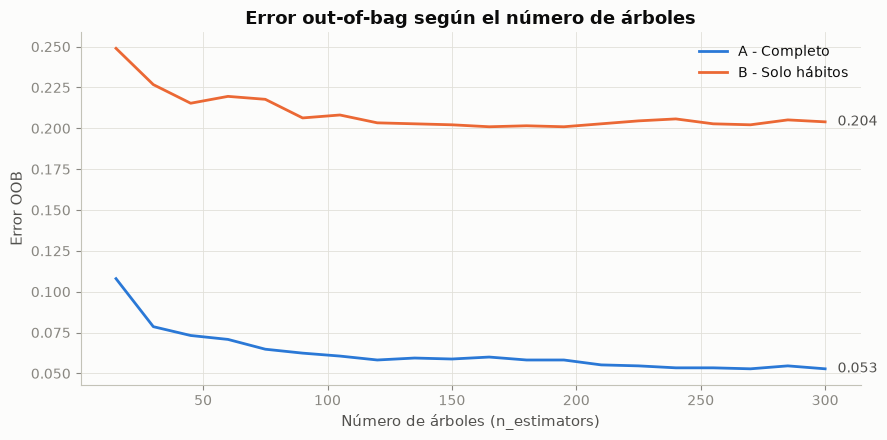

In [23]:
# Cantidades de árboles a evaluar
n_arboles = list(range(15, 301, 15))
errores_oob = {}

for nombre, (X_train, X_test) in DATOS.items():
    # warm_start=True permite agregar árboles al bosque ya entrenado en vez de empezar de cero
    rf_inc = RandomForestClassifier(warm_start=True, oob_score=True,
                                    random_state=SEMILLA, n_jobs=-1)
    errores = []
    for n in n_arboles:
        rf_inc.set_params(n_estimators=n)
        rf_inc.fit(X_train, y_train)
        errores.append(1 - rf_inc.oob_score_)   # error OOB = 1 - precisión OOB
    errores_oob[nombre] = errores

# Gráfica del error OOB en función del número de árboles
fig, ax = plt.subplots(figsize=(9, 4.5))
for (nombre, errores), color in zip(errores_oob.items(), [AZUL, NARANJA]):
    ax.plot(n_arboles, errores, color=color, linewidth=2, label=nombre)
    ax.text(n_arboles[-1] + 5, errores[-1], f"{errores[-1]:.3f}", va="center",
            color=TINTA_SEC, fontsize=10)
ax.set_xlabel("Número de árboles (n_estimators)")
ax.set_ylabel("Error OOB")
ax.set_title("Error out-of-bag según el número de árboles")
ax.legend(loc="upper right")
plt.tight_layout(); guardar_figura("05_error_oob_vs_arboles"); plt.show()

## 3.4 Ajuste de hiperparámetros con `RandomizedSearchCV`

Se buscan los mejores hiperparámetros probando **60 combinaciones aleatorias**, cada una evaluada con **validación cruzada estratificada de 5 particiones** sobre el conjunto de entrenamiento. La métrica a optimizar es el **F1-macro**.

| Hiperparámetro | Qué controla | Valores probados |
|---|---|---|
| `n_estimators` | Número de árboles del bosque | 100, 200, 300, 500 |
| `max_depth` | Profundidad máxima de cada árbol (limita el sobreajuste) | None, 10, 15, 20, 30 |
| `min_samples_split` | Mínimo de muestras para dividir un nodo | 2, 5, 10 |
| `min_samples_leaf` | Mínimo de muestras en cada hoja | 1, 2, 4 |
| `max_features` | Variables candidatas en cada división (decorrelaciona los árboles) | sqrt, log2, 0.5, None (todas) |
| `criterion` | Medida de impureza para escoger las divisiones | gini, entropy |
| `class_weight` | Peso de cada clase | None, balanced |

In [24]:
# Espacio de búsqueda de hiperparámetros
espacio = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 10, 15, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", 0.5, None],
    "criterion": ["gini", "entropy"],
    "class_weight": [None, "balanced"],
}

# Validación cruzada estratificada de 5 particiones (mantiene la proporción de clases)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
busquedas = {}

for nombre, (X_train, X_test) in DATOS.items():
    busqueda = RandomizedSearchCV(
        estimator=RandomForestClassifier(random_state=SEMILLA, n_jobs=-1),
        param_distributions=espacio,
        n_iter=60,              # número de combinaciones aleatorias a evaluar
        scoring="f1_macro",     # métrica a maximizar
        cv=cv,
        random_state=SEMILLA,
        n_jobs=-1,
    )
    busqueda.fit(X_train, y_train)
    busquedas[nombre] = busqueda
    print(f"=== {nombre} ===")
    print(f"Mejor F1-macro en validación cruzada: {busqueda.best_score_:.4f}")
    print(f"Mejores hiperparámetros: {busqueda.best_params_}\n")

=== A - Completo ===
Mejor F1-macro en validación cruzada: 0.9619
Mejores hiperparámetros: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 20, 'criterion': 'entropy', 'class_weight': 'balanced'}

=== B - Solo hábitos ===
Mejor F1-macro en validación cruzada: 0.7870
Mejores hiperparámetros: {'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 15, 'criterion': 'gini', 'class_weight': None}



In [25]:
# Las 5 mejores combinaciones de cada escenario (para analizar la sensibilidad a los hiperparámetros)
for nombre, busqueda in busquedas.items():
    res = pd.DataFrame(busqueda.cv_results_)
    cols = ["param_" + p for p in espacio] + ["mean_test_score", "std_test_score"]
    print(f"=== {nombre} ===")
    display(res.sort_values("rank_test_score")[cols].head(5).round(4))

=== A - Completo ===


,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf,param_max_features,param_criterion,param_class_weight,mean_test_score,std_test_score
51,500,20,2,1,0.5,entropy,balanced,0.9619,0.0125
44,200,30,2,1,None,entropy,NaN,0.9600,0.0095
4,300,15,2,2,0.5,entropy,NaN,0.9563,0.0079
6,100,15,2,2,None,entropy,NaN,0.9551,0.0072
2,200,10,2,1,0.5,entropy,balanced,0.9549,0.0100


=== B - Solo hábitos ===


,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf,param_max_features,param_criterion,param_class_weight,mean_test_score,std_test_score
18,500,15,5,1,log2,gini,NaN,0.7870,0.0269
29,300,20,5,1,log2,gini,balanced,0.7869,0.0338
25,200,None,5,1,0.5,gini,balanced,0.7850,0.0282
46,500,15,2,1,0.5,gini,balanced,0.7842,0.0236
27,300,15,2,1,sqrt,entropy,NaN,0.7834,0.0264


## 3.5 Modelo final (Random Forest ajustado)

`RandomizedSearchCV` reentrena automáticamente el mejor modelo con **todo** el conjunto de entrenamiento (`refit=True`). Ese es el modelo final de cada escenario.

In [26]:
for nombre, busqueda in busquedas.items():
    rf_final = busqueda.best_estimator_
    modelos[nombre]["Random Forest (ajustado)"] = rf_final
    print(f"{nombre}: {rf_final.n_estimators} árboles, "
          f"profundidad máx. real = {max(a.get_depth() for a in rf_final.estimators_)}")

A - Completo: 500 árboles, profundidad máx. real = 18
B - Solo hábitos: 500 árboles, profundidad máx. real = 15


---
# 4. Evaluación de los modelos

Se usan **dos métricas de calidad**, calculadas sobre el **conjunto de prueba** (datos que ningún modelo vio durante el entrenamiento):

| Métrica | Qué mide |
|---|---|
| **Accuracy** | Proporción de predicciones correctas sobre el total de registros |
| **F1-score (macro)** | Combina en un solo valor qué tan acertadas son las predicciones de cada clase y cuántos registros de cada clase detecta el modelo. La versión *macro* calcula el F1 de cada una de las 7 clases y las promedia con el mismo peso, así una clase con mal desempeño no queda oculta. **Es la métrica principal**, y la que se optimizó en la búsqueda de hiperparámetros. |

## 4.1 Función de evaluación

In [27]:
def evaluar(modelo, X_test, y_test):
    # Calcula Accuracy y F1-score (macro) de un modelo sobre el conjunto de prueba
    y_pred = modelo.predict(X_test)
    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
    }

## 4.2 Comparación de modelos

In [28]:
# Evaluación de todos los modelos en ambos escenarios
filas = []
for escenario, dict_modelos in modelos.items():
    X_train, X_test = DATOS[escenario]
    for nombre_modelo, modelo in dict_modelos.items():
        metricas = evaluar(modelo, X_test, y_test)
        # Accuracy en entrenamiento, para detectar sobreajuste (diferencia grande = sobreajuste)
        metricas["Accuracy entrenamiento"] = accuracy_score(y_train, modelo.predict(X_train))
        filas.append({"Escenario": escenario, "Modelo": nombre_modelo, **metricas})

resultados = pd.DataFrame(filas).set_index(["Escenario", "Modelo"])
resultados.round(4)

Accuracy  F1 (macro)  \
Escenario        Modelo                                           
A - Completo     Árbol de decisión           0.9544      0.9531   
                 Random Forest (defecto)     0.9424      0.9401   
                 Random Forest (ajustado)    0.9664      0.9652   
B - Solo hábitos Árbol de decisión           0.7146      0.7053   
                 Random Forest (defecto)     0.7986      0.7896   
                 Random Forest (ajustado)    0.8082      0.7983   

                                           Accuracy entrenamiento  
Escenario        Modelo                                            
A - Completo     Árbol de decisión                         1.0000  
                 Random Forest (defecto)                   1.0000  
                 Random Forest (ajustado)                  1.0000  
B - Solo hábitos Árbol de decisión                         0.9856  
                 Random Forest (defecto)                   0.9856  
                 Random Forest (ajustado)                  0.9604

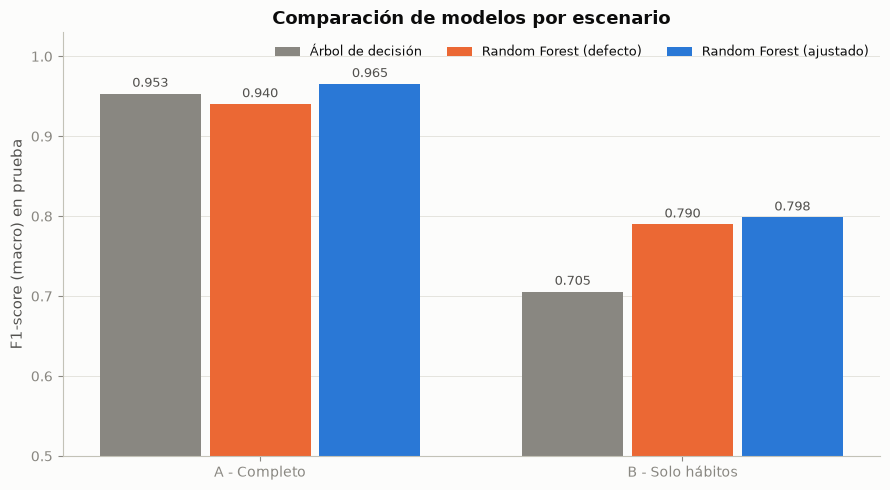

In [29]:
# Gráfica de barras agrupadas: F1-macro de cada modelo en cada escenario
nombres_modelos = list(modelos["A - Completo"].keys())
colores = [GRIS, NARANJA, AZUL]       # el modelo final (ajustado) se resalta en azul
x = np.arange(len(ESCENARIOS))
ancho = 0.26

fig, ax = plt.subplots(figsize=(9, 5))
for i, (nombre_modelo, color) in enumerate(zip(nombres_modelos, colores)):
    valores = [resultados.loc[(esc, nombre_modelo), "F1 (macro)"] for esc in ESCENARIOS]
    barras = ax.bar(x + (i - 1) * ancho, valores, ancho * 0.92, color=color, label=nombre_modelo)
    for b, v in zip(barras, valores):   # valor encima de cada barra
        ax.text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.3f}",
                ha="center", va="bottom", fontsize=9, color=TINTA_SEC)
ax.set_xticks(x, list(ESCENARIOS))
ax.set_ylim(0.5, 1.03)
ax.set_ylabel("F1-score (macro) en prueba")
ax.set_title("Comparación de modelos por escenario")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", ncol=3, fontsize=9)
plt.tight_layout(); guardar_figura("06_comparacion_modelos"); plt.show()

**Análisis de la comparación:**
- **Escenario B (solo hábitos):** aquí se ve con claridad la ventaja del ensamble. Random Forest **mejora el F1-macro en unos 9 puntos** frente al árbol de decisión (de 0,705 a 0,798). El árbol solo **sobreajusta**: casi 99 % en entrenamiento contra 71 % en prueba. Al promediar cientos de árboles se reduce esa varianza.
- **Escenario A (completo):** el árbol solo ya es muy bueno, porque le basta con dividir por `Peso` y `Estatura` (casi una fórmula del IMC). Curiosamente, el Random Forest **por defecto** queda un poco por debajo del árbol. La razón es `max_features="sqrt"`: en cada división solo se consideran 4 de las 19 variables, y muchas veces `Peso` no está entre las candidatas. El modelo **ajustado** usa `max_features=0.5` (la mitad de las variables), recupera esa información y supera a los dos.
- El ajuste de hiperparámetros aporta una mejora moderada (de 1 a 2,5 puntos) frente al Random Forest por defecto. Esto confirma que Random Forest funciona bien "de fábrica", pero que `max_features` es su hiperparámetro más sensible.

## 4.3 F1-score por clase (Random Forest ajustado)

Se calcula el F1-score **de cada nivel de obesidad** por separado, para ver en qué clases se equivoca más el modelo.

In [30]:
# average=None devuelve un F1 para cada clase (en el orden de ORDEN_CLASES)
f1_por_clase = {}
for escenario in ESCENARIOS:
    X_train, X_test = DATOS[escenario]
    y_pred = modelos[escenario]["Random Forest (ajustado)"].predict(X_test)
    f1_por_clase[escenario] = f1_score(y_test, y_pred, labels=ORDEN_CLASES, average=None)

tabla_f1 = pd.DataFrame(f1_por_clase, index=ORDEN_CLASES)
tabla_f1["Registros en prueba"] = y_test.value_counts().reindex(ORDEN_CLASES)
tabla_f1.round(3)

,A - Completo,B - Solo hábitos,Registros en prueba
Insufficient_Weight,0.990,0.835,53
Normal_Weight,0.920,0.655,56
Overweight_Level_I,0.911,0.673,55
Overweight_Level_II,0.966,0.706,58
Obesity_Type_I,0.986,0.832,70
Obesity_Type_II,0.992,0.903,60
Obesity_Type_III,0.992,0.985,65


**Observación:** en el escenario B, las clases con menor F1 son *Normal_Weight*, *Overweight_Level_I* y *Overweight_Level_II*, es decir, los niveles intermedios, que se parecen más entre sí en cuanto a hábitos. Los extremos (peso insuficiente y obesidad II y III) se distinguen mejor.

## 4.4 Matrices de confusión

Las filas son la **clase real** y las columnas la **clase predicha**. La diagonal corresponde a los aciertos. Como las clases están ordenadas de menor a mayor peso, los errores **cerca de la diagonal** son confusiones entre niveles vecinos (por ejemplo, sobrepeso I y II), que son errores "menos graves".

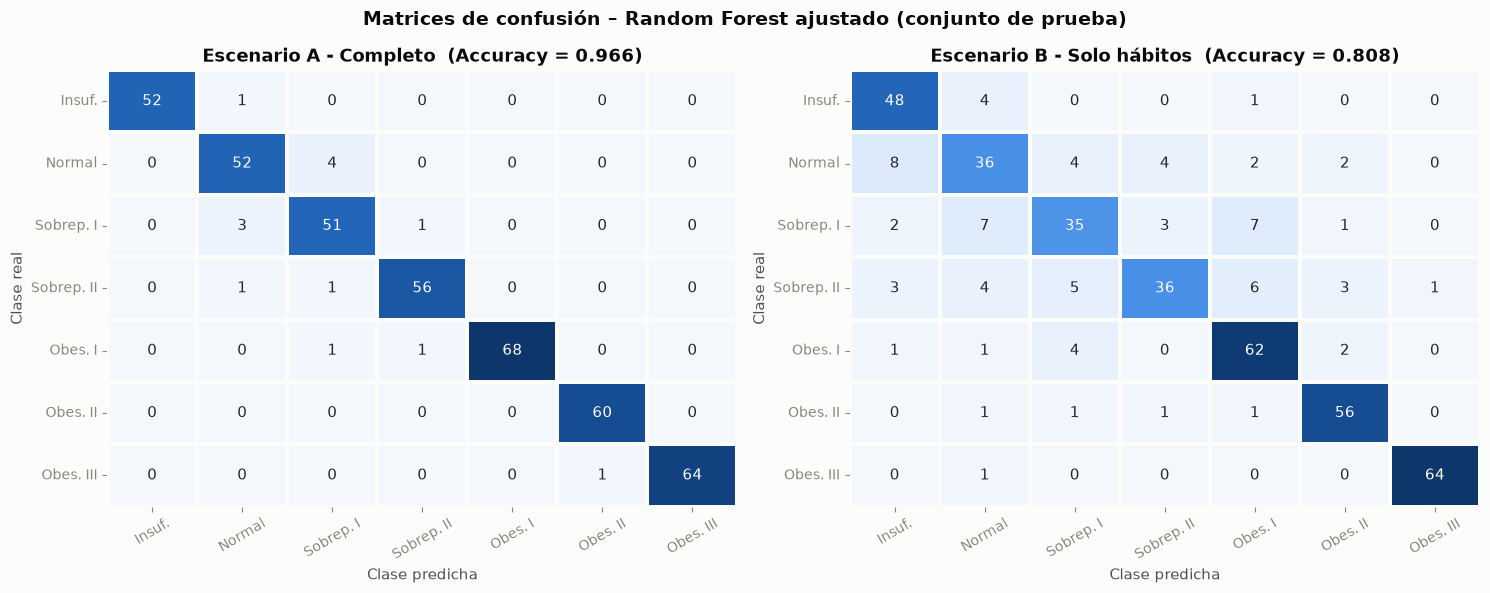

In [31]:
# Etiquetas cortas para que la matriz sea legible
ETIQUETAS_CORTAS = ["Insuf.", "Normal", "Sobrep. I", "Sobrep. II",
                    "Obes. I", "Obes. II", "Obes. III"]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, escenario in zip(axes, ESCENARIOS):
    X_train, X_test = DATOS[escenario]
    y_pred = modelos[escenario]["Random Forest (ajustado)"].predict(X_test)
    mc = confusion_matrix(y_test, y_pred, labels=ORDEN_CLASES)
    sns.heatmap(mc, annot=True, fmt="d", cmap=CMAP_AZUL, cbar=False, ax=ax,
                xticklabels=ETIQUETAS_CORTAS, yticklabels=ETIQUETAS_CORTAS,
                linewidths=1.5, linecolor=FONDO, annot_kws={"fontsize": 11})
    acc = accuracy_score(y_test, y_pred)
    ax.set_title(f"Escenario {escenario}  (Accuracy = {acc:.3f})")
    ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
    ax.tick_params(axis="x", rotation=30); ax.tick_params(axis="y", rotation=0)
    ax.grid(False)                       # sin rejilla encima de las celdas
plt.suptitle("Matrices de confusión – Random Forest ajustado (conjunto de prueba)",
             fontweight="bold", fontsize=14)
plt.tight_layout(); guardar_figura("07_matrices_confusion"); plt.show()

## 4.5 Validación cruzada (estabilidad del modelo)

Un solo conjunto de prueba puede dar un resultado "de suerte". Con **validación cruzada estratificada de 10 particiones** sobre todos los datos se obtiene la media y la desviación estándar del desempeño. Una desviación pequeña indica que el modelo es **estable**.

In [32]:
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMILLA)
filas_cv = []

for escenario, X in ESCENARIOS.items():
    for nombre_modelo in ["Árbol de decisión", "Random Forest (ajustado)"]:
        # Se clona la configuración del modelo y se reentrena en cada una de las 10 particiones
        modelo = modelos[escenario][nombre_modelo]
        cv_res = cross_validate(modelo, X, y, cv=cv10, n_jobs=-1,
                                scoring=["accuracy", "f1_macro"])
        filas_cv.append({
            "Escenario": escenario, "Modelo": nombre_modelo,
            "Accuracy (media ± desv.)": f"{cv_res['test_accuracy'].mean():.4f} ± {cv_res['test_accuracy'].std():.4f}",
            "F1-macro (media ± desv.)": f"{cv_res['test_f1_macro'].mean():.4f} ± {cv_res['test_f1_macro'].std():.4f}",
        })

pd.DataFrame(filas_cv).set_index(["Escenario", "Modelo"])

Accuracy (media ± desv.)  \
Escenario        Modelo                                              
A - Completo     Árbol de decisión                 0.9439 ± 0.0192   
                 Random Forest (ajustado)          0.9688 ± 0.0156   
B - Solo hábitos Árbol de decisión                 0.7433 ± 0.0250   
                 Random Forest (ajustado)          0.8090 ± 0.0239   

                                          F1-macro (media ± desv.)  
Escenario        Modelo                                             
A - Completo     Árbol de decisión                 0.9416 ± 0.0205  
                 Random Forest (ajustado)          0.9676 ± 0.0155  
B - Solo hábitos Árbol de decisión                 0.7337 ± 0.0293  
                 Random Forest (ajustado)          0.8025 ± 0.0245

## 4.6 Importancia de las variables

Random Forest permite medir **qué variables influyen más** en la predicción, de dos formas:

1. **Importancia por impureza (Gini / MDI):** cuánto reduce cada variable la impureza en todas las divisiones de todos los árboles. Se calcula durante el entrenamiento, pero puede favorecer a las variables con muchos valores distintos.
2. **Importancia por permutación:** se desordena al azar una variable en el conjunto de prueba y se mide **cuánto cae el desempeño**. Si cae mucho, el modelo depende de esa variable. Es más confiable porque se calcula sobre datos no vistos.

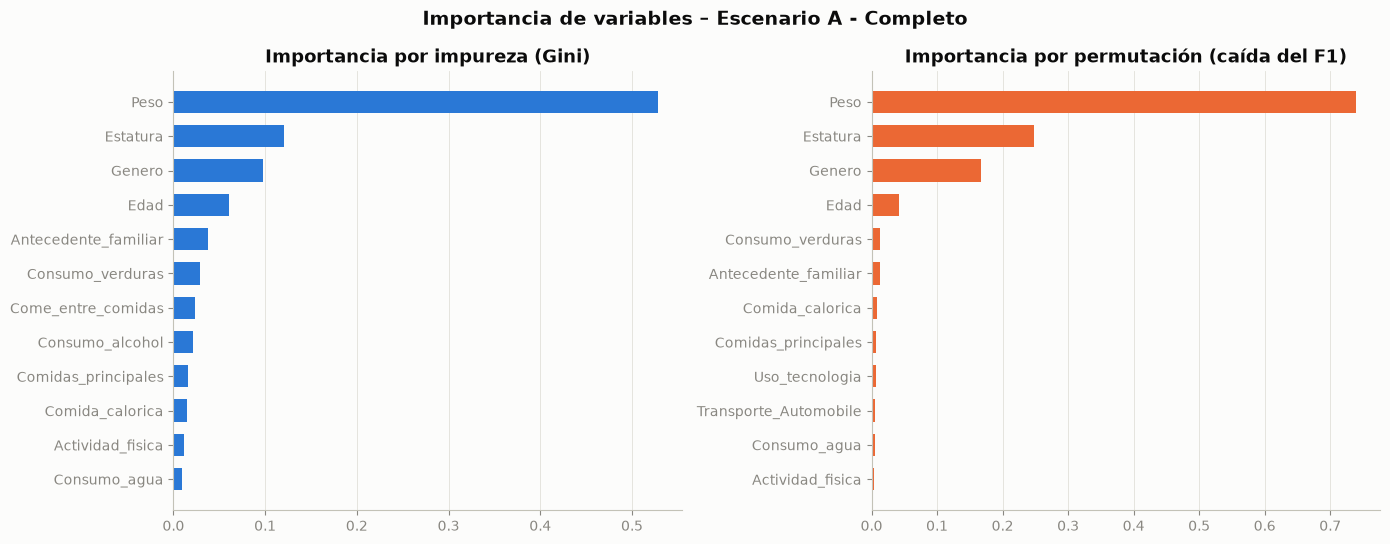

In [33]:
def graficar_importancias(escenario, n=12):
    # Calcula y grafica las importancias Gini y por permutación del modelo ajustado
    X_train, X_test = DATOS[escenario]
    modelo = modelos[escenario]["Random Forest (ajustado)"]

    # 1) Importancia por impureza (viene incorporada en el modelo entrenado)
    imp_gini = pd.Series(modelo.feature_importances_, index=X_train.columns)

    # 2) Importancia por permutación sobre el conjunto de prueba (10 repeticiones)
    perm = permutation_importance(modelo, X_test, y_test, n_repeats=10,
                                  scoring="f1_macro", random_state=SEMILLA, n_jobs=-1)
    imp_perm = pd.Series(perm.importances_mean, index=X_test.columns)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    for ax, imp, titulo, color in zip(
            axes, [imp_gini, imp_perm],
            ["Importancia por impureza (Gini)", "Importancia por permutación (caída del F1)"],
            [AZUL, NARANJA]):
        top = imp.sort_values(ascending=True).tail(n)   # las n más importantes
        ax.barh(top.index, top.values, color=color, height=0.65)
        ax.grid(axis="y", visible=False)
        ax.set_title(titulo)
    plt.suptitle(f"Importancia de variables – Escenario {escenario}",
                 fontweight="bold", fontsize=14)
    plt.tight_layout()
    return imp_gini, imp_perm


imp_A = graficar_importancias("A - Completo")
guardar_figura("08_importancia_escenario_A"); plt.show()

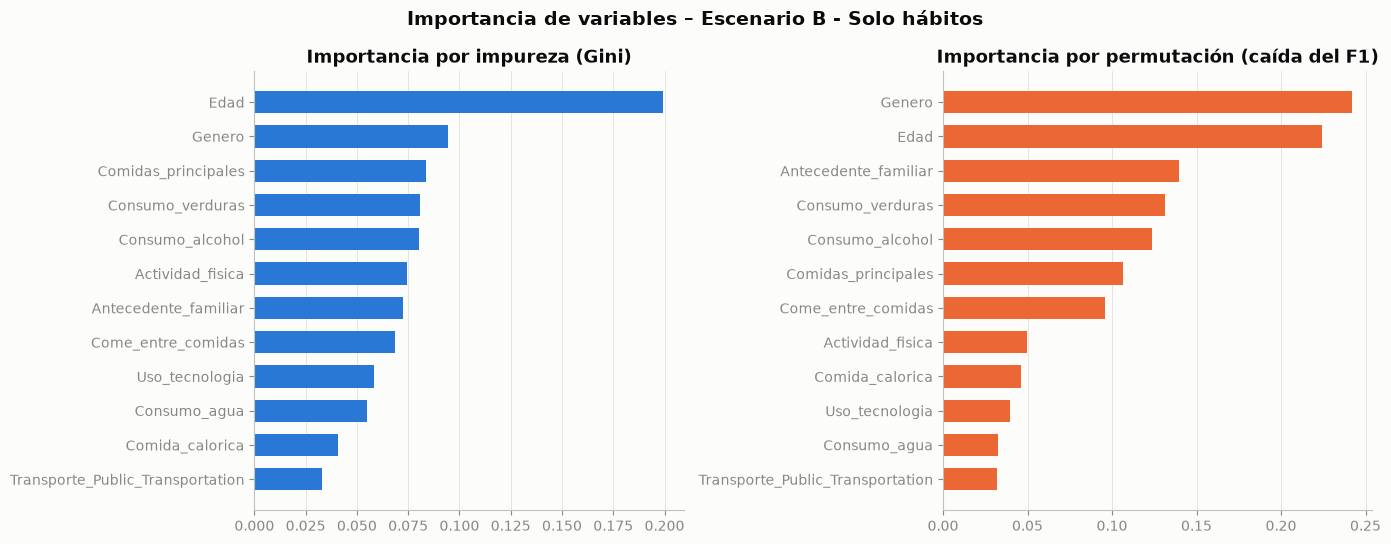

In [34]:
imp_B = graficar_importancias("B - Solo hábitos")
guardar_figura("09_importancia_escenario_B"); plt.show()

In [35]:
# Tabla resumen con las 10 variables más importantes (por permutación) del escenario B
(pd.DataFrame({"Gini": imp_B[0], "Permutación": imp_B[1]})
   .sort_values("Permutación", ascending=False).head(10).round(4))

,Gini,Permutación
Genero,0.0946,0.2419
Edad,0.1993,0.2242
Antecedente_familiar,0.0727,0.1395
Consumo_verduras,0.0806,0.1311
Consumo_alcohol,0.0800,0.1237
Comidas_principales,0.0836,0.1068
Come_entre_comidas,0.0688,0.0961
Actividad_fisica,0.0746,0.0498
Comida_calorica,0.0409,0.0462
Uso_tecnologia,0.0583,0.0398


**Interpretación de la importancia de variables:**
- **Escenario A:** como se esperaba, `Peso` domina por completo, seguido de `Estatura`. El modelo prácticamente reconstruye el IMC.
- **Escenario B:** las variables más importantes son `Edad`, `Genero`, `Antecedente_familiar`, `Consumo_verduras`, `Consumo_alcohol` y `Comidas_principales`. Los hábitos alimenticios y el antecedente familiar sí aportan al diagnóstico, lo que coincide con la literatura médica.
- **Precaución con `Genero`:** su alta importancia se explica en gran parte por el artefacto del dataset visto en la sección 2.7 (Obesidad II casi solo hombres y Obesidad III solo mujeres). Por eso, el excelente desempeño en *Obesity_Type_III* del escenario B (F1 ≈ 0,98) **no debe interpretarse como que los hábitos predicen perfectamente la obesidad mórbida**. Es una limitación de los datos sintéticos.
- La importancia **Gini** y la de **permutación** coinciden en lo general, pero la de permutación castiga menos a las variables con pocos valores (como `Genero`, que es binaria) y por eso las ordena distinto.

## 4.7 Ejemplo de predicción para una persona nueva

Se simula el uso real del sistema: se ingresan los datos de una persona (en el mismo formato de la encuesta) y el modelo devuelve el nivel de obesidad predicho y la **probabilidad de cada clase** (la proporción de árboles que votó por cada una).

In [36]:
# Datos de una persona hipotética (mismo formato que la encuesta original)
persona = pd.DataFrame([{
    "Edad": 28, "Genero": "Male", "Estatura": 1.75, "Peso": 105,
    "Consumo_alcohol": "Sometimes", "Comida_calorica": "yes",
    "Consumo_verduras": 1, "Comidas_principales": 3, "Monitorea_calorias": "no",
    "Fuma": "no", "Consumo_agua": 1, "Antecedente_familiar": "yes",
    "Actividad_fisica": 0, "Uso_tecnologia": 2, "Come_entre_comidas": "Frequently",
    "Transporte": "Automobile",
}])

# Se aplica la MISMA codificación usada en el entrenamiento
persona_cod = codificar(persona)

for escenario, X in ESCENARIOS.items():
    modelo = modelos[escenario]["Random Forest (ajustado)"]
    entrada = persona_cod[X.columns]                 # mismas columnas y mismo orden
    prediccion = modelo.predict(entrada)[0]
    proba = pd.Series(modelo.predict_proba(entrada)[0], index=modelo.classes_)
    print(f"Escenario {escenario} -> predicción: {prediccion}")
    print((proba.reindex(ORDEN_CLASES) * 100).round(1).astype(str).add(" %").to_string(), "\n")

Escenario A - Completo -> predicción: Obesity_Type_I
Insufficient_Weight     0.0 %
Normal_Weight           0.8 %
Overweight_Level_I      0.6 %
Overweight_Level_II     6.0 %
Obesity_Type_I         63.4 %
Obesity_Type_II        29.2 %
Obesity_Type_III        0.0 % 

Escenario B - Solo hábitos -> predicción: Overweight_Level_II
Insufficient_Weight     2.3 %
Normal_Weight          19.6 %
Overweight_Level_I      8.4 %
Overweight_Level_II    26.7 %
Obesity_Type_I         23.0 %
Obesity_Type_II        19.9 %
Obesity_Type_III        0.0 % 



---
# 5. Guardado de los modelos para el despliegue

Se guarda cada modelo final junto con la información necesaria para usarlo después (orden de las columnas, clases y mapeos de codificación). Se usa el módulo **`pickle`** de Python, que *serializa* el objeto: convierte el modelo entrenado, con todos sus árboles, en un archivo binario `.pkl`. Así la aplicación de despliegue puede cargarlo con `pickle.load()` sin volver a entrenar.


In [39]:
CARPETA_MODELOS = Path("modelos")
CARPETA_MODELOS.mkdir(exist_ok=True)

for escenario, X in ESCENARIOS.items():
    paquete = {
        "modelo": modelos[escenario]["Random Forest (ajustado)"],
        "columnas": X.columns.tolist(),          # orden exacto de las variables de entrada
        "clases": ORDEN_CLASES,
        "mapeos": {"binario": MAPEO_BINARIO, "genero": MAPEO_GENERO,
                   "ordinal": MAPEO_ORDINAL, "transporte": CATEGORIAS_TRANSPORTE},
        "metricas_prueba": resultados.loc[(escenario, "Random Forest (ajustado)")].to_dict(),
    }
    archivo = CARPETA_MODELOS / ("rf_escenario_A.pkl" if escenario.startswith("A")
                                 else "rf_escenario_B.pkl")
    # 'wb' = escritura en modo binario; pickle.dump serializa el diccionario completo
    with open(archivo, "wb") as f:
        pickle.dump(paquete, f)
    print(f"Guardado: {archivo}  ({archivo.stat().st_size / 1024 / 1024:.1f} MB)")

Guardado: modelos\rf_escenario_A.pkl  (15.8 MB)
Guardado: modelos\rf_escenario_B.pkl  (32.3 MB)


### Verificación: cargar el modelo guardado

Se carga el archivo `.pkl` como lo haría la aplicación de despliegue y se comprueba que da **exactamente** el mismo resultado que el modelo en memoria.

In [40]:
for escenario in ESCENARIOS:
    archivo = CARPETA_MODELOS / ("rf_escenario_A.pkl" if escenario.startswith("A")
                                 else "rf_escenario_B.pkl")
    # 'rb' = lectura en modo binario; pickle.load reconstruye el diccionario guardado
    with open(archivo, "rb") as f:
        cargado = pickle.load(f)

    X_train, X_test = DATOS[escenario]
    y_pred = cargado["modelo"].predict(X_test[cargado["columnas"]])
    print(f"{escenario}: Accuracy = {accuracy_score(y_test, y_pred):.4f}  |  "
          f"F1 (macro) = {f1_score(y_test, y_pred, average='macro'):.4f}")

A - Completo: Accuracy = 0.9664  |  F1 (macro) = 0.9652
B - Solo hábitos: Accuracy = 0.8082  |  F1 (macro) = 0.7983


---
# 6. Conclusiones

## Resumen de resultados (conjunto de prueba, 417 registros)

| Escenario | Modelo | Accuracy | F1-macro | F1-macro en validación cruzada (10 particiones) |
|---|---|---|---|---|
| A – Completo | Árbol de decisión | 0,954 | 0,953 | 0,942 ± 0,021 |
| A – Completo | **Random Forest ajustado** | **0,966** | **0,965** | **0,968 ± 0,016** |
| B – Solo hábitos | Árbol de decisión | 0,715 | 0,705 | 0,734 ± 0,029 |
| B – Solo hábitos | **Random Forest ajustado** | **0,808** | **0,798** | **0,803 ± 0,025** |

## Conclusiones

1. **Limpieza:** el dataset no tenía valores faltantes, pero sí tenía problemas propios de los datos sintéticos: decimales en variables que en la encuesta son discretas, 27 registros duplicados y categorías con muy pocos registros. Corregirlos dejó 2.084 registros limpios y coherentes con la encuesta original.
2. **Random Forest supera al árbol de decisión individual en ambos escenarios.** La mejora es especialmente grande en el escenario B (+9 puntos de F1), donde el árbol solo sobreajusta. Esto confirma el principio del método: **promediar muchos árboles decorrelacionados reduce la varianza**.
3. **Con peso y estatura (escenario A)** el modelo alcanza un **96,6 % de Accuracy**. Sin embargo, buena parte de ese desempeño viene de que la clase se define con el IMC, así que el modelo reconstruye una fórmula conocida.
4. **Solo con hábitos (escenario B)** el modelo alcanza un **80,8 % de Accuracy** sobre 7 clases (el azar sería ~14 %). Así se demuestra que los hábitos de vida, en especial el antecedente familiar, el consumo de verduras, el alcohol y el número de comidas, sí tienen poder predictivo. Este escenario es el más útil para **prevención**, porque no requiere medir a la persona.
5. La mayoría de los errores del escenario B ocurren **entre niveles vecinos** (peso normal frente a sobrepeso I, sobrepeso I frente a sobrepeso II), es decir, errores de "un nivel", no confusiones extremas.
6. **Hiperparámetros:** `max_features` es el más influyente. El error OOB se estabiliza alrededor de los 100–150 árboles, y agregar más no genera sobreajuste.
7. **Limitaciones:** el 77 % de los datos es sintético (SMOTE), y eso introduce artefactos como la separación total por género en Obesidad II y III. Los resultados del escenario B en esas clases son optimistas y deberían validarse con datos reales antes de usar el modelo en un contexto clínico.

